In [1]:
import pandas as pd

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('../Resources/Revised Final Dataset.csv')
df['Month_Year'] = pd.to_datetime(df['Month_Year'], errors='coerce')
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health,Month_Year
0,Rural,103.9,101.9,103.1,105.5,104.0,2013-01-01
1,Urban,102.3,102.9,101.8,105.4,104.1,2013-01-01
2,Rural+Urban,103.2,102.2,102.7,105.5,104.0,2013-01-01
3,Rural,104.0,102.4,103.1,106.2,104.4,2013-02-01
4,Urban,103.1,104.9,102.3,105.7,104.7,2013-02-01


In [3]:
df.set_index('Month_Year', inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 453 entries, 2013-01-01 to 2025-07-01
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sector          453 non-null    object 
 1   Fruits          453 non-null    float64
 2   Vegetables      453 non-null    float64
 3   Spices          453 non-null    float64
 4   Fuel and light  453 non-null    float64
 5   Health          453 non-null    float64
dtypes: float64(5), object(1)
memory usage: 24.8+ KB


In [5]:
col_order = ['Sector', 'Fruits', 'Vegetables', 'Spices', 'Fuel and light', 'Health']
df = df[col_order]

In [6]:
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health
Month_Year,,,,,,
2013-01-01,Rural,103.9,101.9,103.1,105.5,104.0
2013-01-01,Urban,102.3,102.9,101.8,105.4,104.1
2013-01-01,Rural+Urban,103.2,102.2,102.7,105.5,104.0
2013-02-01,Rural,104.0,102.4,103.1,106.2,104.4
2013-02-01,Urban,103.1,104.9,102.3,105.7,104.7


In [7]:
df = df[df['Sector']=='Rural'].copy()
df = df.asfreq('MS')

In [8]:
df.index.min(), df.index.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2025-07-01 00:00:00'))

In [9]:
pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', length=151, freq='MS')

In [10]:
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

In [11]:
df.index

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', name='Month_Year', length=151, freq='MS')

In [12]:
df.isna().sum()

Sector            0
Fruits            0
Vegetables        0
Spices            0
Fuel and light    0
Health            0
dtype: int64

In [13]:
df[df['Vegetables'].isna()]['Vegetables']
df['Vegetables'].interpolate().loc['2019-03-01':'2019-05-01']

Month_Year
2019-03-01    128.2
2019-04-01    129.3
2019-05-01    133.4
Freq: MS, Name: Vegetables, dtype: float64

In [14]:
df['Vegetables'] = df['Vegetables'].interpolate()
df['Vegetables'].isna().sum()

0

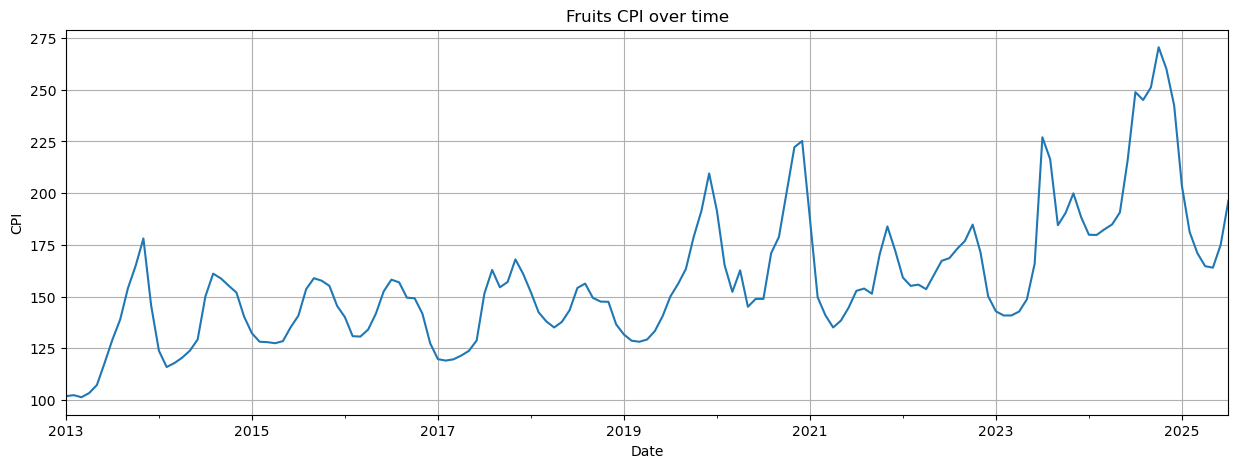

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
df['Vegetables'].plot()
plt.title('Fruits CPI over time')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.grid(True)
plt.show()

In [16]:
from statsmodels.tsa.seasonal import STL
stl = STL(df['Vegetables'], period=12)
result = stl.fit()

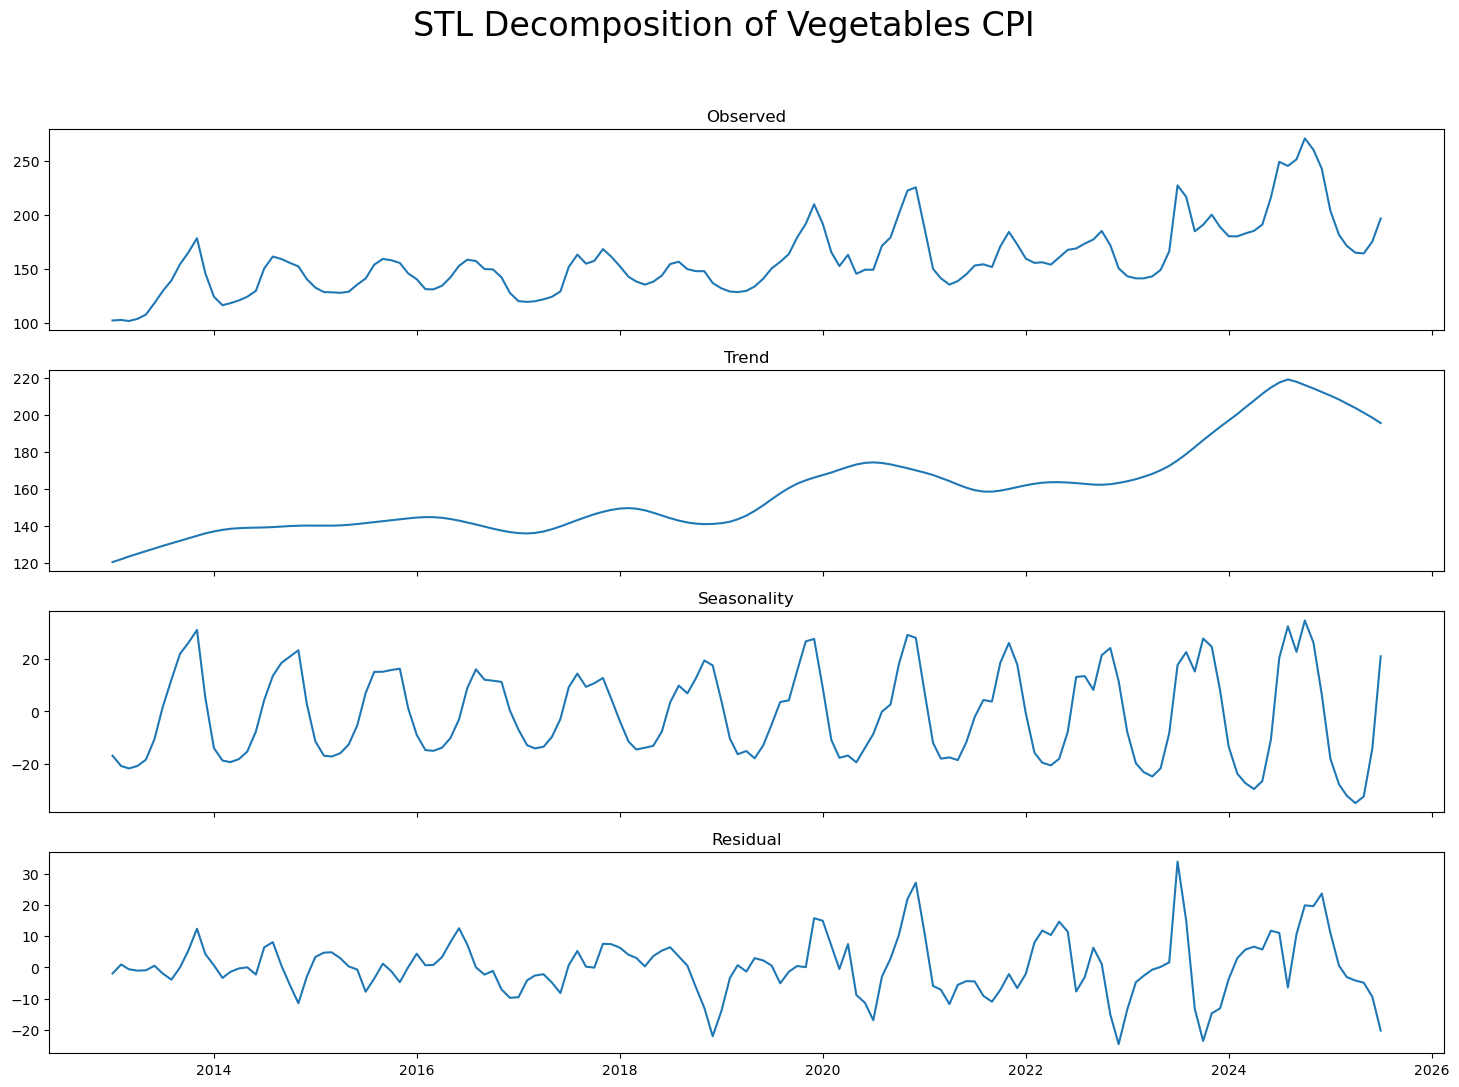

In [17]:
fig, axs = plt.subplots(4, 1, figsize=(18,12), sharex=True)

axs[0].plot(df.index, df['Vegetables'], label='Observed')
axs[0].set_title('Observed')

axs[1].plot(df.index, result.trend, label='Trend')
axs[1].set_title('Trend')

axs[2].plot(df.index, result.seasonal, label='Seasonality')
axs[2].set_title('Seasonality')

axs[3].plot(df.index, result.resid, label='Residual')
axs[3].set_title('Residual')

plt.suptitle('STL Decomposition of Vegetables CPI', fontsize=24)
plt.show()

In [18]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df['Vegetables'])
adf_result

(-0.8938260555160982,
 0.7899987860959641,
 11,
 139,
 {'1%': -3.4782936965183815,
  '5%': -2.882567574015525,
  '10%': -2.5779830117488745},
 1022.3143346683997)

In [19]:
adf_result[0]

-0.8938260555160982

In [20]:
adf_result[1]

0.7899987860959641

In [21]:
#cannot reject null hypothesis as 0.92428 > 0.05

In [22]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

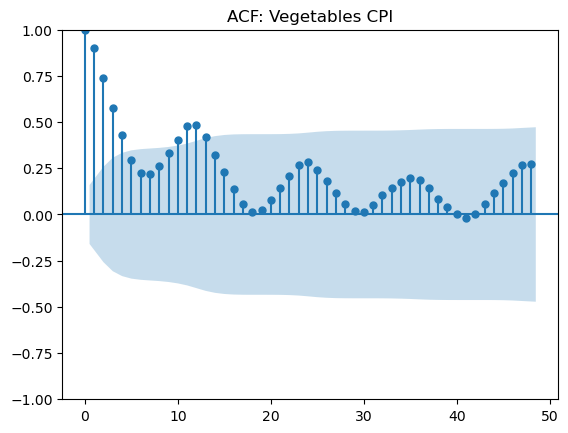

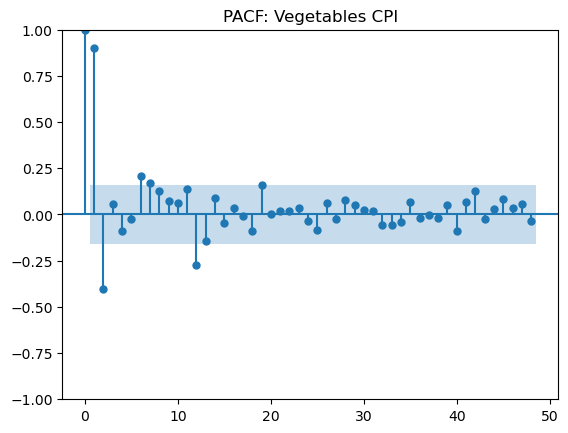

In [23]:
plot_acf(df['Vegetables'], lags=48)
plt.title('ACF: Vegetables CPI')
plt.show()

plot_pacf(df['Vegetables'], lags=48)
plt.title('PACF: Vegetables CPI')
plt.show()

In [24]:
# AR from PACF: sharp drop is from lag 2
# MA from ACF: lags 1 to 3 are significant 

In [25]:
test_size = 12 
train = df['Vegetables'].iloc[0:-test_size]
test = df['Vegetables'].iloc[-test_size:]

In [26]:
from statsmodels.tsa.arima.model import ARIMA

In [27]:
model = ARIMA(train, order=(0,2,1), seasonal_order=(0,1,1,12))
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                    SARIMAX Results                                     
========================================================================================
Dep. Variable:                       Vegetables   No. Observations:                  139
Model:             ARIMA(0, 2, 1)x(0, 1, 1, 12)   Log Likelihood                -484.201
Date:                          Sun, 22 Nov 2026   AIC                            974.401
Time:                                  15:19:57   BIC                            982.886
Sample:                              01-01-2013   HQIC                           977.848
                                   - 07-01-2024                                         
Covariance Type:                            opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9998      3.391     -0.295      0.768      -7.646       5.646
ma.S.L12      -0.6936      0.086     -8.074      0.000      -0.862      -0.525
sigma2       120.7218    405.311      0.298      0.766    -673.673     915.117
===================================================================================
Ljung-Box (L1) (Q):                   8.09   Jarque-Bera (JB):               116.33
Prob(Q):                              0.00   Prob(JB):                         0.00
Heteroskedasticity (H):               3.71   Skew:                             0.43
Prob(H) (two-sided):                  0.00   Kurtosis:                         7.65
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

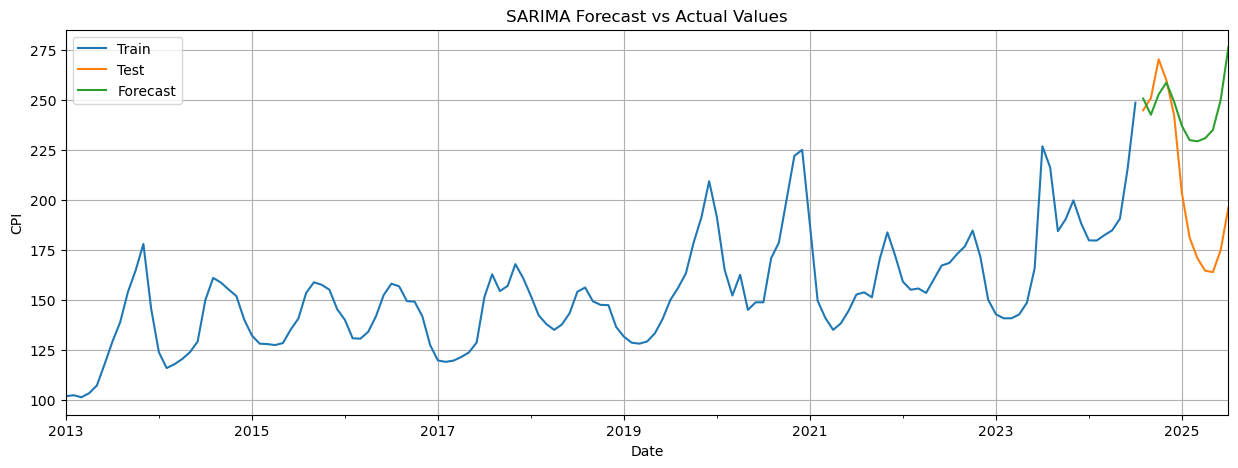

In [28]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [29]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

49.1029385420519

In [30]:
s = 12

p_values = [0, 1, 2]
d_values = [1]
q_values = [0, 1, 2]

P_values = [0, 1, 2]
D_values = [1]
Q_values = [0, 1,2]

In [31]:
param_grid = [((p, d, q), (P, D, Q, s))
 for p in p_values
 for d in d_values
 for q in q_values
 for P in P_values
 for D in D_values
 for Q in Q_values]

len(param_grid)

81

In [32]:
from sklearn.model_selection import TimeSeriesSplit

In [33]:
X = df['Vegetables']
tscv = TimeSeriesSplit(n_splits=3, test_size=12)
tscv

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=12)

In [34]:
len(list(tscv.split(X)))

3

In [35]:
list(tscv.split(X))

[(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
          52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
          65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
          78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
          91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
         104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114]),
  array([115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126])),
 (array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,

In [36]:
from tqdm.notebook import tqdm
import numpy as np

metrics = []

for order, seasonal_order in tqdm(param_grid):
    split_rmse = []

    for train_idx, test_idx in tscv.split(X):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        model = ARIMA(X_train, order=order, seasonal_order=seasonal_order)
        results = model.fit()

        X_pred = results.forecast(steps=len(X_test))
        rmse = np.sqrt(mean_squared_error(X_test, X_pred))
        split_rmse.append(rmse)

    mean_rmse = np.mean(split_rmse)
    std_rmse = np.std(split_rmse)

    metrics.append(
        {'order': order,
         'seasonal_order': seasonal_order,
         'rmse_mean': mean_rmse,
         'rmse_std': std_rmse}
    )

  0%|          | 0/81 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (26 outputs left out)

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [37]:
metrics_df = pd.DataFrame(metrics)
metrics_df

,order,seasonal_order,rmse_mean,rmse_std
0,"(0, 1, 0)","(0, 1, 0, 12)",33.231881,7.520057
1,"(0, 1, 0)","(0, 1, 1, 12)",37.284924,7.296529
2,"(0, 1, 0)","(0, 1, 2, 12)",42.048385,5.763720
3,"(0, 1, 0)","(1, 1, 0, 12)",36.194832,5.508999
4,"(0, 1, 0)","(1, 1, 1, 12)",33.957944,8.113331
...,...,...,...,...
76,"(2, 1, 2)","(1, 1, 1, 12)",37.196234,9.498492
77,"(2, 1, 2)","(1, 1, 2, 12)",39.351540,7.793721
78,"(2, 1, 2)","(2, 1, 0, 12)",43.151642,9.060674
79,"(2, 1, 2)","(2, 1, 1, 12)",38.335832,8.916336


In [38]:
metrics_df.sort_values(by='rmse_mean', ascending=True)

,order,seasonal_order,rmse_mean,rmse_std
67,"(2, 1, 1)","(1, 1, 1, 12)",27.665701,5.329785
64,"(2, 1, 1)","(0, 1, 1, 12)",28.906462,4.374073
70,"(2, 1, 1)","(2, 1, 1, 12)",29.411155,4.161911
68,"(2, 1, 1)","(1, 1, 2, 12)",29.833185,3.753511
71,"(2, 1, 1)","(2, 1, 2, 12)",30.962019,2.823661
...,...,...,...,...
42,"(1, 1, 1)","(2, 1, 0, 12)",48.558131,14.912535
29,"(1, 1, 0)","(0, 1, 2, 12)",49.471724,9.600981
20,"(0, 1, 2)","(0, 1, 2, 12)",49.980067,11.216004
33,"(1, 1, 0)","(2, 1, 0, 12)",50.611609,17.585956


In [39]:
model = ARIMA(train, order=(2,1,1), seasonal_order=(1,1,1,12))
results = model.fit()

results.summary()

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                    SARIMAX Results                                     
========================================================================================
Dep. Variable:                       Vegetables   No. Observations:                  139
Model:             ARIMA(2, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -471.673
Date:                          Sun, 22 Nov 2026   AIC                            955.347
Time:                                  15:22:36   BIC                            972.365
Sample:                              01-01-2013   HQIC                           962.261
                                   - 07-01-2024                                         
Covariance Type:                            opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.1179      0.070     15.900      0.000       0.980       1.256
ar.L2         -0.3455      0.067     -5.147      0.000      -0.477      -0.214
ma.L1         -0.9710      0.098     -9.944      0.000      -1.162      -0.780
ar.S.L12       0.2651      0.188      1.408      0.159      -0.104       0.634
ma.S.L12      -0.9789      1.192     -0.821      0.411      -3.315       1.357
sigma2        86.3513     93.277      0.926      0.355     -96.468     269.171
===================================================================================
Ljung-Box (L1) (Q):                   0.29   Jarque-Bera (JB):               217.38
Prob(Q):                              0.59   Prob(JB):                         0.00
Heteroskedasticity (H):               3.65   Skew:                             1.22
Prob(H) (two-sided):                  0.00   Kurtosis:                         8.96
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

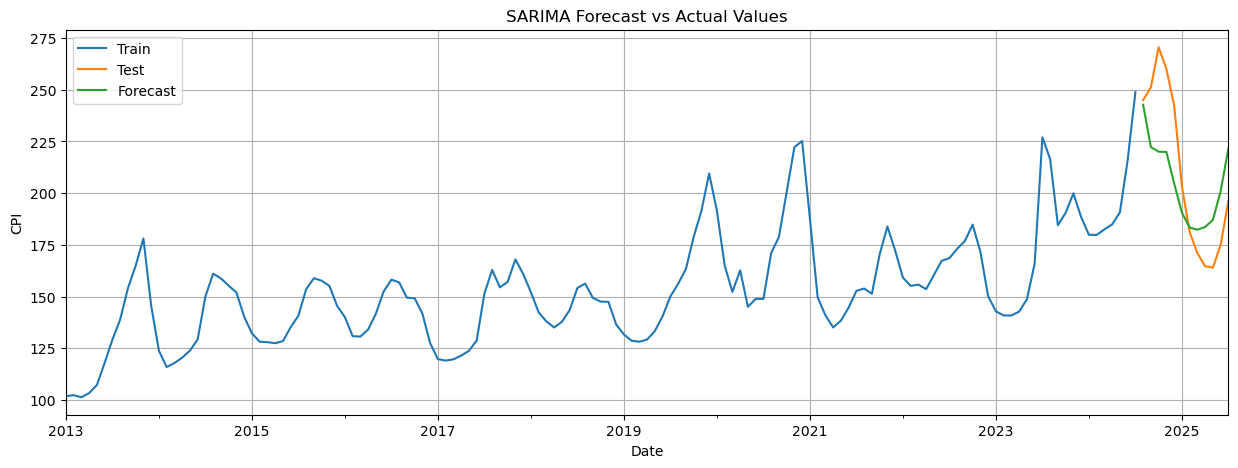

In [40]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [41]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

27.265347872714425

In [42]:
results = model.fit()


import joblib
joblib.dump(results, 'vegetables-rural.pkl')

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


['vegetables-rural.pkl']